# Домашнее задание 4: BERTopic на Lenta.ru

Corus, предобработка, BERTopic (мультиязычный MiniLM, UMAP, HDBSCAN), визуализации, Topic Diversity и UMass. Рубрики датасета и темы по тексту совпадать не обязаны; ниже два прогона с разными гиперпараметрами


In [1]:
%pip install -q corus pandas numpy matplotlib nltk tqdm gensim bertopic sentence-transformers umap-learn hdbscan



[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Установка и импорты

Фиксируется `RANDOM_STATE`, подключаются библиотеки для данных, визуализации, `train_test_split` и NLTK stopwords


In [2]:
import os

os.environ.setdefault("PYDEVD_DISABLE_FILE_VALIDATION", "1")

import re
from collections import Counter
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from tqdm.auto import tqdm

import nltk
from corus import load_lenta
from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
pd.set_option("display.max_colwidth", 120)
np.random.seed(RANDOM_STATE)

nltk.download("stopwords", quiet=True)


True

## Загрузка данных

Файл `lenta-ru-news.csv.gz` при отсутствии или слишком маленьком размере скачивается через `urllib`. Записи читаются через `load_lenta`; `MAX_RECORDS` ограничивает объём для быстрого прогона (`None`, весь корпус)


In [3]:
from itertools import islice

DATA_PATH = Path("lenta-ru-news.csv.gz")
DATA_URL = (
    "https://github.com/yutkin/Lenta.Ru-News-Dataset/"
    "releases/download/v1.0/lenta-ru-news.csv.gz"
)
MIN_FILE_BYTES = 100 * 1024 * 1024
MAX_RECORDS = None

if not DATA_PATH.exists() or DATA_PATH.stat().st_size < MIN_FILE_BYTES:
    urlretrieve(DATA_URL, DATA_PATH)

records = load_lenta(str(DATA_PATH))
if MAX_RECORDS is not None:
    records = islice(records, MAX_RECORDS)

rows = [
    {"title": rec.title, "text": rec.text, "topic": rec.topic}
    for rec in tqdm(records, desc="Loading lenta")
]
df = pd.DataFrame(rows)
df["topic"] = df["topic"].astype(str).str.strip()
df["title"] = df["title"].fillna("").astype(str)
df["text"] = df["text"].fillna("").astype(str)
df = df[(df["topic"] != "") & (df["text"].str.strip() != "")].reset_index(drop=True)
print("shape:", df.shape)
print("topics:", df["topic"].nunique())
df.head(3)


Loading lenta: 0it [00:00, ?it/s]

shape: (739143, 3)
topics: 23


,title,text,topic
0,Названы регионы России с самой высокой смертностью от рака,"Вице-премьер по социальным вопросам Татьяна Голикова рассказала, в каких регионах России зафиксирована наиболее высо...",Россия
1,Австрия не представила доказательств вины российских биатлонистов,Австрийские правоохранительные органы не представили доказательств нарушения российскими биатлонистами антидопинговы...,Спорт
2,Обнаружено самое счастливое место на планете,"Сотрудники социальной сети Instagram проанализировали поставленные пользователями смайлики, геолокации и хештеги и о...",Путешествия


## Разведочный анализ

Смотрим распределение рубрик и длин текстов в словах, строим гистограмму длины и bar chart топ-20 рубрик


Топ-15 тем по числу документов:


,n_docs
topic,
Россия,160516
Мир,136679
Экономика,79538
Спорт,64421
Культура,53802
Бывший СССР,53402
Наука и техника,53136
Интернет и СМИ,44675
Из жизни,27611



Статистика по длине текстов:


,count,mean,std,min,25%,50%,75%,max
text_len_chars,739143.0,1334.963375,554.300790,3.0,976.0,1257.0,1606.0,55386.0
text_len_words,739143.0,180.441962,74.320294,1.0,133.0,170.0,217.0,8091.0


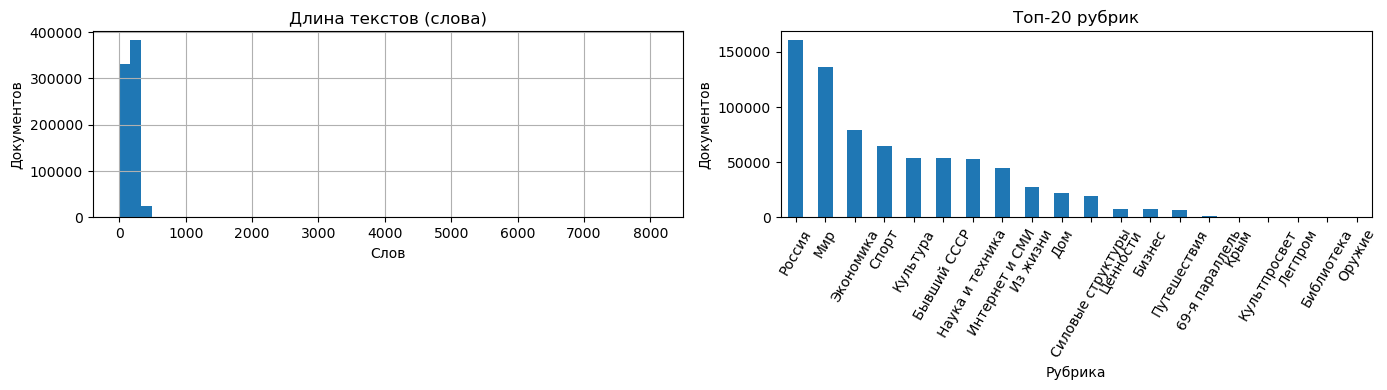

In [4]:
df["text_len_chars"] = df["text"].str.len()
df["text_len_words"] = df["text"].str.split().str.len()

print("Топ-15 тем по числу документов:")
display(df["topic"].value_counts().head(15).to_frame("n_docs"))
print("\nСтатистика по длине текстов:")
display(df[["text_len_chars", "text_len_words"]].describe().T)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df["text_len_words"].hist(bins=50, ax=axes[0])
axes[0].set(title="Длина текстов (слова)", xlabel="Слов", ylabel="Документов")
df["topic"].value_counts().head(20).plot(kind="bar", ax=axes[1])
axes[1].set(title="Топ-20 рубрик", xlabel="Рубрика", ylabel="Документов")
axes[1].tick_params(axis="x", rotation=60)
fig.tight_layout()
plt.show()


Гистограмма длины показывает хвосты, по барам рубрик видно перекос классов, стратификация в подвыборке как раз это учитывает


## Примеры документов

Пять случайных текстов с рубрикой и заголовком, просто посмотреть что внутри


In [5]:
for i, row in enumerate(df.sample(n=5, random_state=RANDOM_STATE).itertuples(index=False), 1):
    print(f"Пример {i}")
    print("Тема:", row.topic)
    print("Заголовок:", row.title)
    print("Текст:", row.text[:500], "...\n")


Пример 1
Тема: Мир
Заголовок: В Висконсине угнали трейлер с сыром на 70 тысяч долларов
Текст: В американском штате Висконсин угнали трейлер с грузом сыра на 70 тысяч долларов. Об этом сообщает NBC News. Дерзкая кража произошла в городе Германтаун в ночь с четверга на пятницу 22 января, но известно о нем стало только в понедельник, 25 января. Неизвестные подогнали тягач к прицепу, где находилась подготовленная к перевозке партия сыра чеддер, и увезли его. Пустой прицеп обнаружили только на следующее утро после того, как полиция объявила сыр в розыск. Грабители действовали по знакомой поли ...

Пример 2
Тема: Мир
Заголовок: Причиной взрыва в мексиканском небоскребе назвали газовый бойлер
Текст: По предварительным данным, причиной мощного взрыва в небоскребе, принадлежащем нефтяной компании Pemex в Мехико, могли стать неполадки в газовом бойлере, который находился в смежном здании. Об этом со ссылкой на анонимный источник в правительстве Мексики сообщает Reuters. Число погибших в результа

Пара примеров чтобы глазами проверить язык и поля перед тяжёлым прогоном


## Предобработка

Тяжёлая морфология для тематики не обязательна, но мусор раздувает c-TF-IDF на стороне BERTopic. Для цепочки токенов (`tokens_clean`, UMass): нижний регистр, `ё` в `е`, без HTML/URL, токены по пробелам, стоп-слова NLTK + новостной список. В трансформер идёт сырой `full_text` (заголовок + текст без этого пайплайна), так в коде и задумано


In [6]:
RU_STOPWORDS = set(stopwords.words("russian"))


def normalize_text(text: str) -> str:
    text = text.lower().replace("ё", "е")
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^а-яa-z0-9\s-]", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def simple_tokenize(text: str):
    return [t for t in text.split() if len(t) >= 3]


df["full_text"] = (df["title"].str.strip() + ". " + df["text"].str.strip()).str.strip()
df["full_text"] = df["full_text"].str.replace(r"^\.\s*", "", regex=True)
df["full_text_norm"] = df["full_text"].map(normalize_text)
df["tokens"] = df["full_text_norm"].map(simple_tokenize)
df["tokens_nostop"] = df["tokens"].map(lambda toks: [t for t in toks if t not in RU_STOPWORDS])
print("После подготовки:")
display(df[["full_text", "full_text_norm", "tokens_nostop"]].head(3))


После подготовки:


,full_text,full_text_norm,tokens_nostop
0,Названы регионы России с самой высокой смертностью от рака. Вице-премьер по социальным вопросам Татьяна Голикова рас...,названы регионы россии с самой высокой смертностью от рака вице-премьер по социальным вопросам татьяна голикова расс...,"[названы, регионы, россии, самой, высокой, смертностью, рака, вице-премьер, социальным, вопросам, татьяна, голикова,..."
1,Австрия не представила доказательств вины российских биатлонистов. Австрийские правоохранительные органы не представ...,австрия не представила доказательств вины российских биатлонистов австрийские правоохранительные органы не представи...,"[австрия, представила, доказательств, вины, российских, биатлонистов, австрийские, правоохранительные, органы, предс..."
2,Обнаружено самое счастливое место на планете. Сотрудники социальной сети Instagram проанализировали поставленные пол...,обнаружено самое счастливое место на планете сотрудники социальной сети instagram проанализировали поставленные поль...,"[обнаружено, самое, счастливое, место, планете, сотрудники, социальной, сети, instagram, проанализировали, поставлен..."


### Частоты до расширения стоп-листа

Топ-30 токенов после базовой очистки и русских стоп-слов


,token,freq
0,года,617075
1,также,412272
2,сообщает,407332
3,россии,392370
4,году,331248
5,время,275352
6,это,254291
7,сша,247377
8,заявил,224927
9,словам,220088


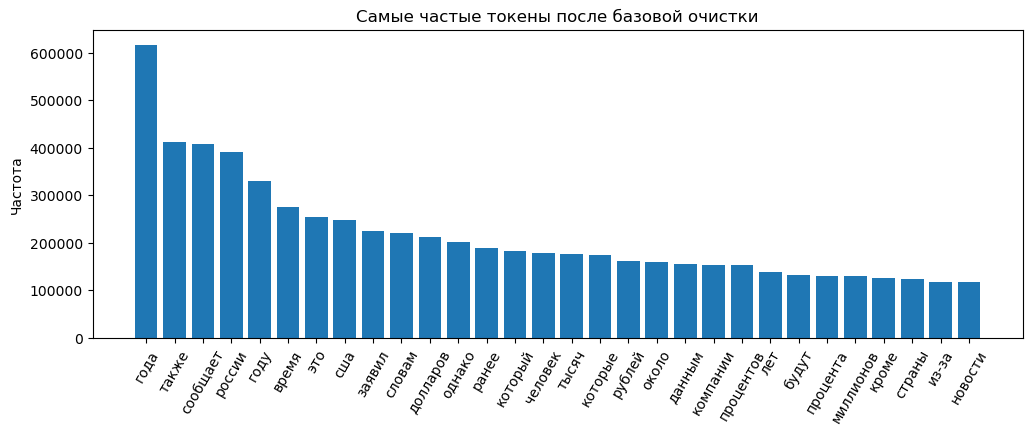

In [7]:
def plot_top_tokens(counter: Counter, title: str, n: int = 30) -> None:
    freq_df = pd.DataFrame(counter.most_common(n), columns=["token", "freq"])
    display(freq_df)
    plt.figure(figsize=(12, 4))
    plt.bar(freq_df["token"], freq_df["freq"])
    plt.title(title)
    plt.xticks(rotation=60)
    plt.ylabel("Частота")
    plt.show()


token_freq = Counter(t for doc in df["tokens_nostop"] for t in doc)
plot_top_tokens(token_freq, "Самые частые токены после базовой очистки")


Без новостного стоп списка в топе сплошные шаблонные слова и темы по ним плохо читаются


### Доменные стоп-слова

К типичным русским стоп-словам добавлены новостные шаблоны («сообщает», «который», названия агентств и т.д.), чтобы топ-слова тем в BERTopic были содержательнее. Тексты для эмбеддингов не режутся, фильтр только на стороне `CountVectorizer`


In [8]:
NEWS_STOPWORDS = {
    "это", "также", "который", "которая", "которые", "которых",
    "сообщает", "сообщил", "сообщила", "заявил", "заявила",
    "словам", "данным", "ранее", "однако", "кроме", "около",
    "года", "году", "лет", "время", "человек",
    "тысяч", "миллионов", "миллиарда", "миллиардов",
    "процентов", "процента", "рублей", "долларов",
    "сша", "россии", "страны", "новости", "из-за", "будут",
    "the", "ria", "риа", "тасс", "при", "передает", "сообщается", "ссылкой",
}
ALL_STOPWORDS = RU_STOPWORDS | NEWS_STOPWORDS
df["tokens_clean"] = df["tokens"].map(lambda toks: [t for t in toks if t not in ALL_STOPWORDS])
df["text_for_vectorizer"] = df["tokens_clean"].map(" ".join)
display(df[["full_text_norm", "text_for_vectorizer"]].head(3))


,full_text_norm,text_for_vectorizer
0,названы регионы россии с самой высокой смертностью от рака вице-премьер по социальным вопросам татьяна голикова расс...,названы регионы самой высокой смертностью рака вице-премьер социальным вопросам татьяна голикова рассказала каких ре...
1,австрия не представила доказательств вины российских биатлонистов австрийские правоохранительные органы не представи...,австрия представила доказательств вины российских биатлонистов австрийские правоохранительные органы представили док...
2,обнаружено самое счастливое место на планете сотрудники социальной сети instagram проанализировали поставленные поль...,обнаружено самое счастливое место планете сотрудники социальной сети instagram проанализировали поставленные пользов...


### Частоты после расширения стоп-листа


,token,freq
0,компании,153942
1,является,114361
2,несколько,113589
3,суд,108076
4,президента,106234
5,результате,106007
6,президент,105227
7,власти,105197
8,пока,104903
9,против,102168


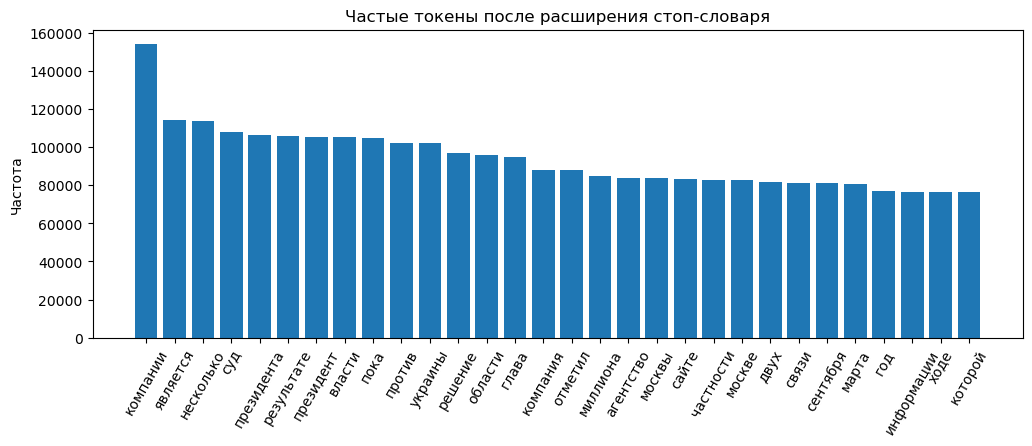

In [9]:
token_freq_clean = Counter(t for doc in df["tokens_clean"] for t in doc)
plot_top_tokens(token_freq_clean, "Частые токены после расширения стоп-словаря")


После своего списка живее, имена и редкие слова без лемматизации всё равно торчат и это ок


## Подвыборка для BERTopic

Стратифицированно берём 50 000 документов по рубрике Lenta (темы с одним документом отбрасываются, чтобы `stratify` был валиден)


In [10]:
topic_counts = df["topic"].value_counts()
df_for_sampling = df[df["topic"].isin(topic_counts[topic_counts >= 2].index)].copy()
print("Исходный размер:", df.shape)
print("После фильтра рубрик:", df_for_sampling.shape)
rare_topics = topic_counts[topic_counts < 2]
print("Удалённые темы:")
display(rare_topics)


Исходный размер: (739143, 11)
После фильтра рубрик: (739141, 11)
Удалённые темы:


topic
МедНовости    1
Сочи          1
Name: count, dtype: int64

In [11]:
SAMPLE_SIZE = 50000
sample_df, _ = train_test_split(
    df_for_sampling,
    train_size=SAMPLE_SIZE,
    stratify=df_for_sampling["topic"],
    random_state=RANDOM_STATE,
)
sample_df = sample_df.reset_index(drop=True)
print(sample_df.shape)
display(sample_df["topic"].value_counts().head(15).to_frame("n_docs"))


(50000, 11)


,n_docs
topic,
Россия,10858
Мир,9246
Экономика,5380
Спорт,4358
Культура,3640
Бывший СССР,3612
Наука и техника,3594
Интернет и СМИ,3022
Из жизни,1868


Пятьдесят тысяч со стратификацией по рубрике чтобы не потерять мелкие темы, рубрики с одним документом выкинул иначе `stratify` ломается


## BERTopic: первый прогон (baseline)

Почему такой пайплайн. Энкодер `paraphrase-multilingual-MiniLM-L12-v2`, небольшой мультиязычный sentence-transformer, на русском работает приемлемо и не требует большого GPU. UMAP здесь стандартный способ сжать эмбеддинги перед кластеризацией (косинусная геометрия в исходном пространстве, у BERTopic это обычный выбор). HDBSCAN удобен тем, что число тем не задаётся вручную и явно выделяется шум `-1`. Топ-токены тем, c-TF-IDF на CountVectorizer (1 и 2 граммы + стоп-лист): интерпретируемые слова без отдельного морфологического пайплайна


In [15]:
import os

os.environ["USE_TORCH"] = "1"

from sklearn.feature_extraction.text import CountVectorizer
from sentence_transformers import SentenceTransformer
from umap import UMAP
from hdbscan import HDBSCAN
from bertopic import BERTopic

EMBEDDING_MODEL_NAME = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
embedding_model = SentenceTransformer(EMBEDDING_MODEL_NAME)
docs = sample_df["full_text"].tolist()


def summarize_topic_run(topic_model, assignments, head: int = 15) -> tuple[int, float]:
    info = topic_model.get_topic_info()
    display(info.head(head))
    n_topics = int((info["Topic"] != -1).sum())
    labels = np.asarray(assignments)
    noise_share = float((labels == -1).mean())
    print("Число тем (без -1):", n_topics)
    print("Доля шума (-1):", round(noise_share, 4))
    return n_topics, noise_share


umap_baseline = UMAP(
    n_neighbors=15,
    n_components=5,
    min_dist=0.0,
    metric="cosine",
    random_state=RANDOM_STATE,
)
hdbscan_baseline = HDBSCAN(
    min_cluster_size=150,
    min_samples=30,
    metric="euclidean",
    cluster_selection_method="eom",
    prediction_data=True,
)
vectorizer_baseline = CountVectorizer(
    stop_words=list(ALL_STOPWORDS),
    ngram_range=(1, 2),
    min_df=10,
    max_df=0.5,
)

topic_model = BERTopic(
    embedding_model=embedding_model,
    umap_model=umap_baseline,
    hdbscan_model=hdbscan_baseline,
    vectorizer_model=vectorizer_baseline,
    language="multilingual",
    calculate_probabilities=True,
    verbose=True,
)


In [17]:
topics, probs = topic_model.fit_transform(docs)
sample_df["bertopic_topic"] = topics


2026-03-28 18:25:47,950 - BERTopic - Embedding - Transforming documents to embeddings.


Batches:   0%|          | 0/1563 [00:00<?, ?it/s]

2026-03-28 18:34:41,034 - BERTopic - Embedding - Completed ✓
2026-03-28 18:34:41,035 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-03-28 18:35:13,203 - BERTopic - Dimensionality - Completed ✓
2026-03-28 18:35:13,204 - BERTopic - Cluster - Start clustering the reduced embeddings
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current p

In [18]:
n_topics_found, noise_share = summarize_topic_run(topic_model, topics)


,Topic,Count,Name,Representation,Representative_Docs
0,-1,18446,-1_нато_боевиков_иг_ирака,"[нато, боевиков, иг, ирака, боевики, причастности, днр, порошенко, би, лукашенко]",[Витренко наградила Каддафи знаком бойца антинатовского сопротивления. Прогрессивная социалистическая партия Украины...
1,0,3389,0_матче_счетом_матча_цска,"[матче, счетом, матча, цска, сборная, чемпионате, тренер, очков, кубка, чемпионов]","[Месси забил пять голов ""Байеру"" в Лиге чемпионов. Испанская ""Барселона"" в ответном матче 1/8 финала Лиги чемпионов ..."
2,1,2499,1_взятки_ук рф_суд москвы_приговор,"[взятки, ук рф, суд москвы, приговор, адвоката, пресечения, следственного, адвокаты, генпрокуратуры, юкоса]",[Владимира Квачкова оставили под стражей до 18 сентября. Мосгорсуд признал законным продление срока содержания под с...
3,2,2142,2_ввп_цб_мвф_втб,"[ввп, цб, мвф, втб, триллиона, банки, кредитов, сбербанк, капитала, сбербанка]","[""ВТБ 24"" будет выдавать каждый пятый ипотечный кредит в России. Банк ""ВТБ 24"" (розничная ""дочка"" ВТБ) планирует в 2..."
4,3,1708,3_избирателей_тимошенко_цик_кпрф,"[избирателей, тимошенко, цик, кпрф, кандидатуру, ющенко, избирательных, отставке, госдуму, лдпр]",[Ющенко потребовал признать его президентом по итогам первого тура выборов. Виктор Ющенко требует от Верховного суда...
5,4,1418,4_исследователи_животное_днк_животные,"[исследователи, животное, днк, животные, птиц, клетки, собак, исследователей, мозга, животного]","[Исследователи выяснили местоположение ""компаса"" птиц. Исследователи выяснили месторасположение структур, при помощи..."
6,5,1134,5_медиа_вконтакте_сайтов_вещание,"[медиа, вконтакте, сайтов, вещание, media, сайты, хакеры, рекламу, редактора, wi fi]",[Несколько тысяч российских сайтов стали распространителями трояна. Неизвестные злоумышленники разместили на несколь...
7,6,950,6_автономии_израильские_израильских_израильской,"[автономии, израильские, израильских, израильской, израилем, израильского, ливана, ha, секторе, aretz]",[Израильские вертолеты уничтожили дженинских функционеров ФАТХ и ХАМАС. Израильские вертолеты поздно вечером во втор...
8,7,893,7_nasa_планеты_космического_орбиту,"[nasa, планеты, космического, орбиту, спутник, спутника, космической, космос, поверхности, космических]","[Ракета-носитель ""Космос-3М"" вывела на орбиту два российских спутника. В 6:00 четверга по московскому времени с косм..."
9,8,818,8_газпром_кубометров_нефть_газпрома,"[газпром, кубометров, нефть, газпрома, баррелей, добычи, газопровода, добычу, газпрому, роснефть]","[""Газпром"" удвоит закупки газа в Азербайджане. Российская газовая монополия ""Газпром"" в 2011 году закупит у Азербайд..."


Число тем (без -1): 55
Доля шума (-1): 0.3689


Первый замер сколько кластеров и какая доля `-1` без ручного K, с ним потом сравниваю второй прогон


## Второй прогон (tuned)

От baseline: выше `n_neighbors` у UMAP; в HDBSCAN меньше `min_cluster_size` и `min_samples` (мельче кластеры). В `CountVectorizer`: ниже `min_df` (редкие n-граммы проходят чаще) и ниже `max_df` (жёстче отсекаю слишком частые). Итог по числу тем и шуму, в таблице ниже (у меня tuned дал больше тем и чуть больше `-1`)


In [19]:
umap_tuned = UMAP(
    n_neighbors=30,
    n_components=5,
    min_dist=0.0,
    metric="cosine",
    random_state=RANDOM_STATE,
)
hdbscan_tuned = HDBSCAN(
    min_cluster_size=100,
    min_samples=10,
    metric="euclidean",
    cluster_selection_method="eom",
    prediction_data=True,
)
vectorizer_tuned = CountVectorizer(
    stop_words=list(ALL_STOPWORDS),
    ngram_range=(1, 2),
    min_df=8,
    max_df=0.45,
)

topic_model_tuned = BERTopic(
    embedding_model=embedding_model,
    umap_model=umap_tuned,
    hdbscan_model=hdbscan_tuned,
    vectorizer_model=vectorizer_tuned,
    language="multilingual",
    calculate_probabilities=True,
    verbose=True,
)


In [20]:
topics_tuned, probs_tuned = topic_model_tuned.fit_transform(docs)
sample_df["bertopic_topic_tuned"] = topics_tuned


2026-03-28 18:35:36,460 - BERTopic - Embedding - Transforming documents to embeddings.


Batches:   0%|          | 0/1563 [00:00<?, ?it/s]

2026-03-28 18:44:25,237 - BERTopic - Embedding - Completed ✓
2026-03-28 18:44:25,239 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-03-28 18:45:09,671 - BERTopic - Dimensionality - Completed ✓
2026-03-28 18:45:09,672 - BERTopic - Cluster - Start clustering the reduced embeddings
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current p

In [21]:
n_topics_tuned, noise_share_tuned = summarize_topic_run(topic_model_tuned, topics_tuned)


,Topic,Count,Name,Representation,Representative_Docs
0,-1,19573,-1_боевиков_киргизии_нато_иг,"[боевиков, киргизии, нато, иг, следователи, колонии, следственного, ирака, ракеты, виновным]",[Генпрокуратура заявила о новых делах против Ходорковского. Заместитель генерального прокурора РФ Александр Звягинце...
1,0,3340,0_матче_счетом_матч_матча,"[матче, счетом, матч, матча, лиги, цска, сборная, чемпионате, минуте, тренер]","[ЦСКА оказался между двух ""Спартаков"" в чемпионате России по футболу. Московский ""Спартак"" догнал земляков из ЦСКА в..."
2,1,1900,1_избирателей_тимошенко_цик_кпрф,"[избирателей, тимошенко, цик, кпрф, кандидатуру, ющенко, избирательных, отставке, парламентских, госдуму]",[Юлия Тимошенко скрыла свои доходы от избирателей. Лидер БЮТ Юлия Тимошенко не сдержала свое обещание перед избирате...
3,2,1356,2_жилья_недвижимости_квартир_жилье,"[жилья, недвижимости, квартир, жилье, метр, квадратный, квадратный метр, недвижимость, аренды, квадратов]",[Рынок новостроек Петербурга показал разнонаправленную динамику цен. На рынке строящейся недвижимости Санкт-Петербур...
4,3,1333,3_журнале_исследователи_животное_днк,"[журнале, исследователи, животное, днк, животные, птиц, клетки, собак, исследователей, мозга]",[Ученые прочитали геном «живого ископаемого». Ученые установили последовательность генома латимерии (Latimeria chalu...
5,4,1254,4_землетрясения_землетрясение_мчс_взрывное,"[землетрясения, землетрясение, мчс, взрывное, взрывное устройство, результате взрыва, произошел взрыв, шахте, спасат...","[В провинции Сычуань произошло новое землетрясение. Землетрясение магнитудой 6,1 произошло в субботу в китайской про..."
6,5,844,5_палестинской_автономии_израильские_палестинцев,"[палестинской, автономии, израильские, палестинцев, израильских, израильской, израильского, израилем, ливана, ha]",[Израильтяне проводят спецоперации в Хевроне и Наблусе. Во вторник утром израильские войска вошли в два города на За...
7,6,809,6_фильме_картины_прокат_картине,"[фильме, картины, прокат, картине, съемки, картина, сериала, сценарий, режиссера, главную роль]",[Звезда «Трона» сыграет пирата в фильме о Питере Пэне. Гаррет Хедлунд сыграет капитана Крюка в фильме Warner Bros. «...
8,7,781,7_газпром_кубометров_нефть_газпрома,"[газпром, кубометров, нефть, газпрома, баррелей, баррель, опек, топлива, добычи, кубометров газа]","[""Газпром"" удвоит закупки газа в Азербайджане. Российская газовая монополия ""Газпром"" в 2011 году закупит у Азербайд..."
9,8,633,8_фестиваля_театра_фестиваль_премию,"[фестиваля, театра, фестиваль, премию, жюри, режиссера, спектакль, театр, приз, премия]","[В Третьяковке вручили премию ""Хрустальная Турандот"". Вечером 17 июня в Москве в Третьяковской галерее состоялась то..."


Число тем (без -1): 75
Доля шума (-1): 0.3915


In [22]:
comparison = pd.DataFrame(
    {
        "Прогон": ["baseline", "tuned"],
        "Число тем_без_1": [n_topics_found, n_topics_tuned],
        "доля_шума": [noise_share, noise_share_tuned],
    }
)
display(comparison)

if noise_share_tuned < noise_share:
    print(
        "По доле -1 второй прогон лучше baseline; смотрю ещё на топ-слова тем — "
        "если темы размылись, это плохой знак."
    )
elif noise_share_tuned > noise_share:
    print("Второй прогон дал больше шума; имеет смысл вернуться к baseline или подобрать параметры заново.")
else:
    print("Доля шума почти совпала; ориентир — число тем и читаемость топ-слов.")

# Крупные кластеры BERTopic и какая рубрика Lenta внутри них чаще всего (без AMI — для глаз)
_rubric = sample_df.assign(_bt=topics_tuned)
rows = []
for tid in sorted(x for x in _rubric["_bt"].unique() if x != -1):
    sub = _rubric[_rubric["_bt"] == tid]
    vc = sub["topic"].value_counts()
    rows.append(
        {
            "bertopic_id": tid,
            "n_docs": len(sub),
            "рубрика_1": vc.index[0],
            "доля_рубрики_1": round(vc.iloc[0] / len(sub), 3),
            "рубрика_2": vc.index[1] if len(vc) > 1 else "",
        }
    )
rubric_mix = pd.DataFrame(rows).sort_values("n_docs", ascending=False).head(15)
print("Крупнейшие темы BERTopic и доминирующая рубрика Lenta внутри кластера:")
display(rubric_mix)


,Прогон,Число тем_без_1,доля_шума
0,baseline,55,0.36892
1,tuned,75,0.39146


Второй прогон дал больше шума; имеет смысл вернуться к baseline или подобрать параметры заново.
Крупнейшие темы BERTopic и доминирующая рубрика Lenta внутри кластера:


,bertopic_id,n_docs,рубрика_1,доля_рубрики_1,рубрика_2
0,0,3340,Спорт,0.937,Из жизни
1,1,1900,Россия,0.495,Бывший СССР
2,2,1356,Дом,0.712,Россия
3,3,1333,Наука и техника,0.452,Из жизни
4,4,1254,Россия,0.455,Мир
5,5,844,Мир,0.940,Россия
6,6,809,Культура,0.930,Интернет и СМИ
7,7,781,Экономика,0.790,Бизнес
8,8,633,Культура,0.829,Россия
9,9,611,Мир,0.763,Россия


Два прогона это компромисс между числом тем долей шума и читаемостью слов, второй не обязан бить первый по `-1`, что брать под графики решаю в следующем блоке


### Модель для графиков и метрик

Ниже в `best_topic` попадают темы из tuned, у меня он дал больше тем и чуть больше доли `-1`, чем baseline; так оставил для обсуждения более мелкой гранулярности. Если нужен минимум шума на этом же сплите, логичнее взять `topic_model` / `topics` / `probs`


In [23]:
best_model = topic_model_tuned
best_topics = topics_tuned
best_probs = probs_tuned
sample_df["best_topic"] = best_topics
best_topic_info = best_model.get_topic_info()


## Визуализации

### Топ-слова по темам

Таблица топ-10 слов для первых тем и интерактивный bar chart BERTopic


In [24]:
top_topics_to_show = best_topic_info[best_topic_info["Topic"] != -1].head(12)["Topic"].tolist()
for topic_id in top_topics_to_show:
    print(f"=== Topic {topic_id} ===")
    print(best_model.get_topic(topic_id)[:10])
    print()


=== Topic 0 ===
[('матче', 0.02765580757525922), ('счетом', 0.02606682363751174), ('матч', 0.024202964435601722), ('матча', 0.023657125221673795), ('лиги', 0.023533867229662303), ('цска', 0.02211990295678558), ('сборная', 0.020236660229523307), ('чемпионате', 0.019683168693762833), ('минуте', 0.019395445758189096), ('тренер', 0.019032880784362726)]

=== Topic 1 ===
[('избирателей', 0.018371410874214848), ('тимошенко', 0.017545056876578688), ('цик', 0.014155524287337946), ('кпрф', 0.011242714105094405), ('кандидатуру', 0.010615172056820278), ('ющенко', 0.009979289023751546), ('избирательных', 0.009473968545946697), ('отставке', 0.00849442299915223), ('парламентских', 0.00819684988360756), ('госдуму', 0.007803828601333649)]

=== Topic 2 ===
[('жилья', 0.03960377637852926), ('недвижимости', 0.028978726509627), ('квартир', 0.025245148415100768), ('жилье', 0.02145560574367023), ('метр', 0.019866286898557156), ('квадратный', 0.018827597804766935), ('квадратный метр', 0.018638833951364467), (

Смотрю глазами что топ читается как один или два сюжета без откровенного мусора


In [25]:
fig_barchart = best_model.visualize_barchart(top_n_topics=12, n_words=10)
fig_barchart.show()


По высоте баров видно не слишком ли ровно разметало c-TF-IDF, если совсем плоско кластер может быть размытый


### Документы в 2D (UMAP)

Случайные 5000 документов: эмбеддинги тем же энкодером, отдельный UMAP в 2D, раскраска по теме (топ-12 + шум + прочие)


Batches:   0%|          | 0/79 [00:00<?, ?it/s]

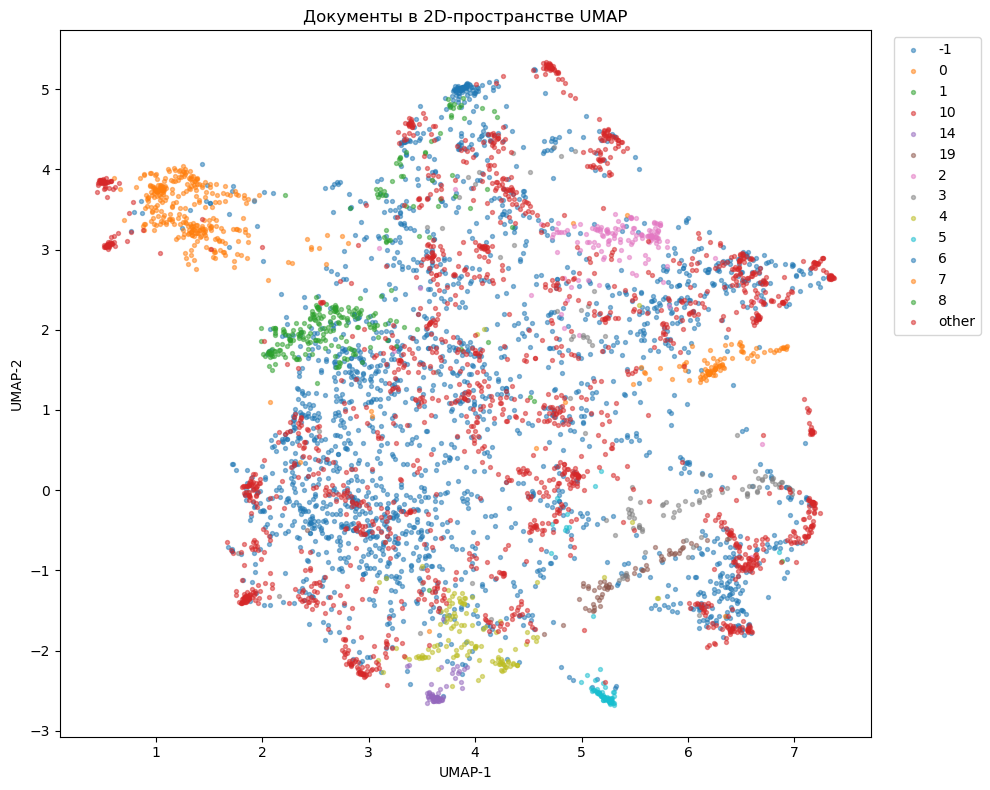

In [26]:
viz_n = 5000
viz_df = sample_df.sample(viz_n, random_state=RANDOM_STATE).copy()
viz_docs = viz_df["full_text"].tolist()
viz_topics = viz_df["best_topic"].tolist()
viz_embeddings = embedding_model.encode(viz_docs, show_progress_bar=True, batch_size=64)
umap_2d = UMAP(
    n_neighbors=30,
    n_components=2,
    min_dist=0.0,
    metric="cosine",
    random_state=RANDOM_STATE,
)
viz_2d = umap_2d.fit_transform(viz_embeddings)
plot_df = pd.DataFrame({"x": viz_2d[:, 0], "y": viz_2d[:, 1], "topic_id": viz_topics})
top_topic_ids = (
    plot_df[plot_df["topic_id"] != -1]["topic_id"]
    .value_counts()
    .head(12)
    .index
    .tolist()
)
plot_df["topic_plot"] = plot_df["topic_id"].apply(
    lambda x: str(x) if x in top_topic_ids else ("-1" if x == -1 else "other")
)
plt.figure(figsize=(10, 8))
for label, part in plot_df.groupby("topic_plot"):
    plt.scatter(part["x"], part["y"], s=8, alpha=0.5, label=label)
plt.title("Документы в 2D-пространстве UMAP")
plt.xlabel("UMAP-1")
plt.ylabel("UMAP-2")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


Это отдельный UMAP в 2D по эмбеддингам, не тот что внутри пайплайна BERTopic, для общей картины, островки и шум от HDBSCAN обычное дело


### Распределение вероятностей по темам

Три случайных документа, у которых тема не шум (`best_topic != -1`); для первого из них, `visualize_distribution`: распределение вероятностей по темам


In [27]:
example_docs = sample_df[sample_df["best_topic"] != -1].sample(3, random_state=RANDOM_STATE)
for i, row in enumerate(example_docs.itertuples(index=False), 1):
    print(f"=== Документ {i} ===")
    print("Исходная рубрика:", row.topic)
    print("BERTopic topic:", row.best_topic)
    print("Заголовок:", row.title)
    print("Текст:", row.text[:500], "...\n")


=== Документ 1 ===
Исходная рубрика: Россия
BERTopic topic: 18
Заголовок: Бекетова похоронят на Новосходненском кладбище 
Текст: Главного редактора газеты «Химкинская правда» Михаила Бекетова похоронят 11 апреля на Новосходненском кладбище. Об этом в своем твиттере сообщила адвокат умершего журналиста Сталина Гуревич. Панихида по главному редактору пройдет в Москве в Доме журналиста, уточнила РИА Новости руководитель фонда помощи Бекетову Людмила Федотова. Ранее в фонде Бекетова просили похоронить журналиста в черте Химок, на Новокуркинском или Новолужинском кладбище. однако в администрации города ответили, что на этих кл ...

=== Документ 2 ===
Исходная рубрика: Россия
BERTopic topic: 14
Заголовок: В Коми горят заповедные леса
Текст: 18 июля в Коми сгорело 8 тысяч гектаров тайги. В республике на общей площади 31 тысяча гектаров сейчас зафиксирован 261 лесной пожар.За сутки ликвидированно 23 пожара на площади 546 гектаров, еще 37 пожаров на площади 1300 гектаров локализовано. В борьбе 

In [28]:
fig_dist = best_model.visualize_distribution(best_probs[example_docs.index[0]])
fig_dist.show()


Если текст на стыке сюжетов нормально что заметная масса уходит в несколько топиков


## Формальные метрики

Topic Diversity: какая доля слов среди top-10 по темам уникальна (чем больше, тем меньше повторов между темами). UMass в Gensim по `tokens_clean`; абсолютное значение сильно зависит от токенизации и стоп-слов, с чужими статьями почти не сравниваю


In [29]:
from gensim.corpora import Dictionary
from gensim.models.coherencemodel import CoherenceModel

valid_topic_ids = [t for t in best_topic_info["Topic"] if t != -1]
topic_words = [[w for w, _ in best_model.get_topic(tid)[:10]] for tid in valid_topic_ids]
print("Число тем для оценки:", len(topic_words))
print("Пример темы:", topic_words[0] if topic_words else None)


Число тем для оценки: 75
Пример темы: ['матче', 'счетом', 'матч', 'матча', 'лиги', 'цска', 'сборная', 'чемпионате', 'минуте', 'тренер']


In [30]:
def topic_diversity(topic_words, top_k: int = 10) -> float:
    all_words = [w for topic in topic_words for w in topic[:top_k]]
    if not all_words:
        return 0.0
    return len(set(all_words)) / len(all_words)


td_score = topic_diversity(topic_words, top_k=10)
print("Topic Diversity:", round(td_score, 4))


Topic Diversity: 0.948


In [31]:
texts_for_coherence = sample_df["tokens_clean"].tolist()
dictionary = Dictionary(texts_for_coherence)
corpus = [dictionary.doc2bow(text) for text in texts_for_coherence]
coherence_model = CoherenceModel(
    topics=topic_words,
    texts=texts_for_coherence,
    corpus=corpus,
    dictionary=dictionary,
    coherence="u_mass",
)
umass_score = coherence_model.get_coherence()
print("UMass Coherence:", round(umass_score, 4))


UMass Coherence: -3.219


In [34]:
metrics_df = pd.DataFrame({
    "Метрика": ["Topic Diversity", "UMass"],
    "Значение": [td_score, umass_score],
})
display(metrics_df)


,Метрика,Значение
0,Topic Diversity,0.948000
1,UMass,-3.218987


TD показывает насколько top слова в разных темах не дублируют друг друга, UMass только ориентир на моих токенах, чужие цифры не трогаю


## Итоговый анализ

Корпус через Corus 739 143 записи (три колонки); для BERTopic, стратифицированно 50 000 документов по рубрике. В сохранённом прогоне: baseline, 55 тем, шум `−1` ≈0,37; tuned, 75 тем, шум ≈0,39. По доле шума выигрывает baseline; tuned мельчит темы.

Топ-слова по кластерам узнаваемые (спорт, суды, нефть/банки, кино, выборы и т.д.), но это не копия рубрик Lenta: в таблице смешения у крупных тем редко бывает одна рубрика около 100 %.

Формальные метрики посчитаны для tuned (как `best_model` в ячейках): Topic Diversity ≈0,948, UMass ≈−3,22 (UMass, ориентир, зависит от токенизации).

Дальше: `merge_topics`, подбор HDBSCAN, энкодер покрупнее под русский, при желании лемматизация.
